# Pneumonia Detection — Domain Generalization
## Leave-One-Domain-Out (LODO) Evaluation Protocol

### Why this is real DG
Each fold trains on 3 datasets and tests on the **completely held-out 4th dataset** —
not a single image from the test domain is seen during training.
This is the standard protocol used in DomainBed, MixStyle, and FACT papers.

### The 4 folds
| Fold | Train on | Test on (unseen) |
|------|----------|------------------|
| 1 | RSNA + NIH + CheXpert | Kermany |
| 2 | Kermany + NIH + CheXpert | RSNA |
| 3 | Kermany + RSNA + CheXpert | NIH |
| 4 | Kermany + RSNA + NIH | CheXpert ← hardest |

### Your FYP contribution
Compare two models on all 4 folds:
- **Baseline**: ERM (standard training, no DG tricks)
- **DG model**: DenseNet121 + MixStyle + Focal Loss + augmentation

Show that DG model has better average AUC and smaller performance variance across folds.
That delta — even if small — is a valid, defensible research contribution.

### Runtime on A100
- Cell 4 (download): ~25 min once
- Each fold: ~25 min (Phase A + B)
- 4 folds × 2 models = ~200 min total
- **Run all folds overnight or across sessions — each fold saves its checkpoint**

In [ ]:
# ============================================================
# CELL 1 — Installs + imports
# ============================================================
!pip install -q albumentations pydicom kaggle \
             opencv-python-headless pillow tqdm \
             matplotlib seaborn scikit-learn

import os, json, random, warnings
import numpy as np
import tensorflow as tf
import albumentations as A
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
import pandas as pd
warnings.filterwarnings('ignore')

print('TF:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
tf.keras.mixed_precision.set_global_policy('float32')
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print('Ready')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 92.3 MB/s eta 0:00:00
TF: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Ready


In [ ]:
# ============================================================
# CELL 2 — Drive + global config
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

BASE     = '/content/drive/MyDrive/FYP_Pneumonia_DG'
IMG_SIZE = 224
BATCH    = 32
MEAN     = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD      = np.array([0.229, 0.224, 0.225], dtype=np.float32)
LR_A     = 3e-4
LR_B     = 3e-5
EPOCHS_A = 12
EPOCHS_B = 25
MAX_PER_DOMAIN = 2000  # cap per (domain, class) to prevent flooding

# # The 4 domains
# DOMAINS = ['kermany', 'rsna', 'nih', 'chexpert']

# # Leave-one-domain-out folds
# # Each fold: (fold_name, test_domain, [train_domains])
# LODO_FOLDS = [
#     ('fold1_test_kermany',  'kermany',  ['rsna', 'nih', 'chexpert']),
#     ('fold2_test_rsna',     'rsna',     ['kermany', 'nih', 'chexpert']),
#     ('fold3_test_nih',      'nih',      ['kermany', 'rsna', 'chexpert']),
#     ('fold4_test_chexpert', 'chexpert', ['kermany', 'rsna', 'nih']),
# ]

# Kermany used for pretraining only — not in LODO evaluation
# LODO runs on 3 adult/mixed-adult domains only
DOMAINS        = ['kermany', 'rsna', 'nih', 'chexpert']  # all data still downloaded
LODO_DOMAINS   = ['rsna', 'nih', 'chexpert']             # only these in evaluation

LODO_FOLDS = [
    ('fold1_test_rsna',     'rsna',     ['nih', 'chexpert']),
    ('fold2_test_nih',      'nih',      ['rsna', 'chexpert']),
    ('fold3_test_chexpert', 'chexpert', ['rsna', 'nih']),
]

for d in [
    f'{BASE}/data/kermany/NORMAL',   f'{BASE}/data/kermany/PNEUMONIA',
    f'{BASE}/data/rsna/NORMAL',      f'{BASE}/data/rsna/PNEUMONIA',
    f'{BASE}/data/nih/NORMAL',       f'{BASE}/data/nih/PNEUMONIA',
    f'{BASE}/data/chexpert/NORMAL',  f'{BASE}/data/chexpert/PNEUMONIA',
    f'{BASE}/checkpoints', f'{BASE}/results/metrics', f'{BASE}/results/gradcam',
]:
    os.makedirs(d, exist_ok=True)

# Note: data is stored FLAT per domain (no train/test subfolders)
# The LODO split is done in memory — one domain is entirely held out.

def count_imgs(folder):
    if not os.path.exists(folder): return 0
    return len([f for f in os.listdir(folder)
                if f.lower().endswith(('.jpg','.jpeg','.png'))])

def save_img(arr, path):
    """Resize to 224 + CLAHE contrast normalization + save.
    Applied once at download time to normalize scanner differences."""
    if arr.dtype != np.uint8:
        arr = ((arr - arr.min()) / (arr.max() - arr.min() + 1e-7) * 255).astype(np.uint8)
    if len(arr.shape) == 2:
        arr = cv2.cvtColor(arr, cv2.COLOR_GRAY2RGB)
    arr = cv2.resize(arr, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LANCZOS4)
    lab = cv2.cvtColor(arr, cv2.COLOR_RGB2LAB)
    lab[:,:,0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(lab[:,:,0])
    Image.fromarray(cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)).save(path, quality=92)

print(f'BASE: {BASE}')
print('LODO folds:')
for name, test, train in LODO_FOLDS:
    print(f'  {name}: train={train}, test={test}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE: /content/drive/MyDrive/FYP_Pneumonia_DG
LODO folds:
  fold1_test_rsna: train=['nih', 'chexpert'], test=rsna
  fold2_test_nih: train=['rsna', 'chexpert'], test=nih
  fold3_test_chexpert: train=['rsna', 'nih'], test=chexpert


In [ ]:
# ============================================================
# CELL 3 — Kaggle credentials
# ============================================================
from google.colab import files
cfg = '/root/.config/kaggle/kaggle.json'
if not os.path.exists(cfg):
    print('Upload kaggle.json')
    up = files.upload()
    os.makedirs('/root/.config/kaggle', exist_ok=True)
    with open(cfg, 'wb') as f: f.write(list(up.values())[0])
    os.chmod(cfg, 0o600)
print('Kaggle ready')

Upload kaggle.json


Saving kaggle(1).json to kaggle(1).json
Kaggle ready


In [ ]:
# ============================================================
# CELL 4 — Download all 4 datasets (flat structure, run once)
#
# Data is stored flat: data/{domain}/NORMAL/ and PNEUMONIA/
# No train/test split here — LODO handles splits in memory.
# ============================================================
import zipfile, glob as G, pydicom

# ── KERMANY ──────────────────────────────────────────────────
if count_imgs(f'{BASE}/data/kermany/PNEUMONIA') > 100:
    print(f'Kermany OK ({count_imgs(BASE+"/data/kermany/PNEUMONIA")} P)')
else:
    print('Downloading Kermany...')
    !kaggle datasets download -d paultimothymooney/chest-xray-pneumonia \
        -p /tmp/kermany --unzip -q
    src = '/tmp/kermany/chest_xray'
    # Merge all splits (train+val+test) into one flat folder
    for sp in ['train', 'val', 'test']:
        for ln in ['NORMAL', 'PNEUMONIA']:
            sd = f'{src}/{sp}/{ln}'
            if not os.path.exists(sd): continue
            for fn in tqdm(os.listdir(sd), desc=f'kermany {sp}/{ln}', leave=False):
                dst = f'{BASE}/data/kermany/{ln}/{fn}'
                if not os.path.exists(dst):
                    try: save_img(np.array(Image.open(f'{sd}/{fn}').convert('RGB')), dst)
                    except: pass
    print(f'Kermany done: {count_imgs(BASE+"/data/kermany/PNEUMONIA")} P, '
          f'{count_imgs(BASE+"/data/kermany/NORMAL")} N')

# ── RSNA ─────────────────────────────────────────────────────
if count_imgs(f'{BASE}/data/rsna/PNEUMONIA') > 100:
    print(f'RSNA OK ({count_imgs(BASE+"/data/rsna/PNEUMONIA")} P)')
else:
    print('Downloading RSNA...')
    os.makedirs('/tmp/rsna', exist_ok=True)
    !kaggle competitions download -c rsna-pneumonia-detection-challenge -p /tmp/rsna
    for zf in G.glob('/tmp/rsna/*.zip'):
        with zipfile.ZipFile(zf) as z: z.extractall('/tmp/rsna')
    lcsv = next(iter(G.glob('/tmp/rsna/**/stage_2_train_labels.csv', recursive=True) +
                     G.glob('/tmp/rsna/**/*.csv', recursive=True)))
    df = pd.read_csv(lcsv).groupby('patientId')['Target'].max().reset_index()
    dcm = {os.path.splitext(os.path.basename(f))[0]: f
           for f in G.glob('/tmp/rsna/**/*.dcm', recursive=True)}
    for lv, ln in [(0,'NORMAL'), (1,'PNEUMONIA')]:
        ids = df[df['Target']==lv]['patientId'].tolist()
        random.shuffle(ids); ids = ids[:6000]
        for pid in tqdm(ids, desc=f'rsna {ln}', leave=False):
            if pid not in dcm: continue
            dst = f'{BASE}/data/rsna/{ln}/{pid}.jpg'
            if os.path.exists(dst): continue
            try: save_img(pydicom.dcmread(dcm[pid]).pixel_array.astype(np.float32), dst)
            except: pass
    print(f'RSNA done: {count_imgs(BASE+"/data/rsna/PNEUMONIA")} P, '
          f'{count_imgs(BASE+"/data/rsna/NORMAL")} N')

# ── NIH ──────────────────────────────────────────────────────
# Only ~1300 true Pneumonia in 112k images.
# Keep ALL pneumonia; sample 2x normals. Nothing more.
if count_imgs(f'{BASE}/data/nih/PNEUMONIA') > 100:
    print(f'NIH OK ({count_imgs(BASE+"/data/nih/PNEUMONIA")} P)')
else:
    print('Downloading NIH (~45 min)...')
    os.makedirs('/tmp/nih', exist_ok=True)
    !kaggle datasets download -d nih-chest-xrays/data -p /tmp/nih --unzip -q
    mc = next(iter(G.glob('/tmp/nih/**/Data_Entry*.csv', recursive=True) +
                   G.glob('/tmp/nih/**/*.csv', recursive=True)))
    df_n = pd.read_csv(mc)
    lc = [c for c in df_n.columns if 'finding' in c.lower() or 'label' in c.lower()][0]
    ic = [c for c in df_n.columns if 'image' in c.lower() or 'file' in c.lower()][0]
    df_n['bin'] = df_n[lc].apply(
        lambda x: 1 if 'Pneumonia' in str(x)
        else (0 if str(x).strip() == 'No Finding' else -1))
    df_pos = df_n[df_n['bin']==1]
    df_neg = df_n[df_n['bin']==0].sample(
        n=min(len(df_pos)*2, (df_n['bin']==0).sum()), random_state=42)
    print(f'  NIH usable: {len(df_pos)} P, {len(df_neg)} N')
    img_idx = {}
    for root, _, fls in os.walk('/tmp/nih'):
        for fn in fls:
            if fn.lower().endswith(('.png','.jpg','.jpeg')):
                img_idx[fn] = os.path.join(root, fn)
    for df_part, ln in [(df_pos,'PNEUMONIA'), (df_neg,'NORMAL')]:
        for _, row in tqdm(df_part.iterrows(), total=len(df_part),
                           desc=f'nih {ln}', leave=False):
            src = img_idx.get(row[ic])
            if src is None: continue
            dst = f'{BASE}/data/nih/{ln}/{row[ic]}'
            if os.path.exists(dst): continue
            try: save_img(np.array(Image.open(src).convert('RGB')), dst)
            except: pass
    print(f'NIH done: {count_imgs(BASE+"/data/nih/PNEUMONIA")} P, '
          f'{count_imgs(BASE+"/data/nih/NORMAL")} N')

# ── CHEXPERT ─────────────────────────────────────────────────
# Strict labels: PNEUMONIA = Consolidation==1 OR Pneumonia==1
#                NORMAL    = No Finding==1
#                Frontal views only. Drop uncertain (-1).
if count_imgs(f'{BASE}/data/chexpert/PNEUMONIA') > 100:
    print(f'CheXpert OK ({count_imgs(BASE+"/data/chexpert/PNEUMONIA")} P)')
else:
    print('Downloading CheXpert...')
    os.makedirs('/tmp/chexpert', exist_ok=True)
    !kaggle datasets download -d ashery/chexpert \
        -p /tmp/chexpert --unzip -q 2>/dev/null || \
     kaggle datasets download -d willarevalo/chexpert-v10-small \
        -p /tmp/chexpert --unzip -q
    df_c = pd.read_csv(G.glob('/tmp/chexpert/**/*.csv', recursive=True)[0])
    cidx = {}
    for root, _, fls in os.walk('/tmp/chexpert'):
        for fn in fls:
            if fn.lower().endswith(('.jpg','.jpeg','.png')):
                cidx[fn] = os.path.join(root, fn)
    def res_chex(p):
        full = os.path.join('/tmp/chexpert', p)
        return full if os.path.exists(full) else cidx.get(os.path.basename(p))
    df_c['rp'] = df_c['Path'].apply(res_chex)
    df_c = df_c[df_c['rp'].notna()].copy()
    if 'Frontal/Lateral' in df_c.columns:
        df_c = df_c[df_c['Frontal/Lateral'] == 'Frontal']
    pos = pd.Series(False, index=df_c.index)
    if 'Consolidation' in df_c.columns: pos |= (df_c['Consolidation'] == 1.0)
    if 'Pneumonia'     in df_c.columns: pos |= (df_c['Pneumonia']     == 1.0)
    neg = pd.Series(False, index=df_c.index)
    if 'No Finding'    in df_c.columns: neg  = (df_c['No Finding']    == 1.0)
    df_pos = df_c[pos].sample(frac=1, random_state=42).reset_index(drop=True)
    df_neg = df_c[neg].sample(frac=1, random_state=42).reset_index(drop=True)
    print(f'  CheXpert usable: {len(df_pos)} P, {len(df_neg)} N')
    for df_part, ln in [(df_pos,'PNEUMONIA'), (df_neg,'NORMAL')]:
        for i, (_, row) in enumerate(tqdm(df_part.iterrows(), total=len(df_part),
                                          desc=f'chexpert {ln}', leave=False)):
            dst = f'{BASE}/data/chexpert/{ln}/img_{i:05d}.jpg'
            if os.path.exists(dst): continue
            try: save_img(np.array(Image.open(row['rp']).convert('RGB')), dst)
            except: pass
    print(f'CheXpert done: {count_imgs(BASE+"/data/chexpert/PNEUMONIA")} P, '
          f'{count_imgs(BASE+"/data/chexpert/NORMAL")} N')

# ── Summary ───────────────────────────────────────────────────
print('\n' + '='*50)
for dom in DOMAINS:
    n = count_imgs(f'{BASE}/data/{dom}/NORMAL')
    p = count_imgs(f'{BASE}/data/{dom}/PNEUMONIA')
    print(f'  {dom:<12}  N={n:5}  P={p:5}  Total={n+p}')
print('='*50)

Kermany OK (1529 P)
100% 3.66G/3.66G [03:51<00:00, 17.0MB/s]



RSNA done: 6000 P, 6000 N
Dataset URL: https://www.kaggle.com/datasets/nih-chest-xrays/data
License(s): CC0-1.0
  NIH usable: 1431 P, 2862 N


NIH done: 1431 P, 2862 N
CheXpert OK (500 P)

  kermany       N= 1583  P= 4271  Total=5854
  rsna          N= 7776  P= 6967  Total=14743
  nih           N= 2862  P= 1431  Total=4293
  chexpert      N=  500  P=  500  Total=1000


In [ ]:
# ============================================================
# CELL 5 — MixStyle + Focal Loss + model builder
# ============================================================
import tensorflow as tf

class MixStyle(tf.keras.layers.Layer):
    """Interpolates feature map style statistics across batch samples.
    Applied on (B,7,7,C) spatial features before GAP — correct placement."""
    def __init__(self, alpha=0.1, p=0.5, eps=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.alpha=alpha; self.p=p; self.eps=eps
    def _mix(self, x):
        x=tf.cast(x,tf.float32); B=tf.shape(x)[0]
        mu=tf.reduce_mean(x,axis=[1,2],keepdims=True)
        sig=tf.sqrt(tf.math.reduce_variance(x,axis=[1,2],keepdims=True)+self.eps)
        xn=(x-mu)/sig
        g1=-tf.math.log(tf.random.uniform([B,1,1,1],1e-8,1.))/self.alpha
        g2=-tf.math.log(tf.random.uniform([B,1,1,1],1e-8,1.))/self.alpha
        lam=g1/(g1+g2); perm=tf.random.shuffle(tf.range(B))
        return xn*(lam*sig+(1-lam)*tf.gather(sig,perm))+(lam*mu+(1-lam)*tf.gather(mu,perm))
    def call(self,x,training=None):
        if not training: return x
        return tf.cond(tf.random.uniform([])<self.p,
                       lambda:self._mix(x), lambda:tf.cast(x,tf.float32))
    def get_config(self):
        c=super().get_config(); c.update({'alpha':self.alpha,'p':self.p,'eps':self.eps}); return c

class FocalBCE(tf.keras.losses.Loss):
    """Focal Loss — down-weights easy examples, prevents collapse."""
    def __init__(self,gamma=2.0,alpha=0.75,ls=0.05,**kw):
        super().__init__(**kw); self.gamma=gamma; self.alpha=alpha; self.ls=ls
    def call(self,yt,yp):
        yt=tf.cast(yt,tf.float32); yp=tf.cast(yp,tf.float32)
        if len(yp.shape)>len(yt.shape): yp=tf.squeeze(yp,-1)
        yt=yt*(1-self.ls)+0.5*self.ls
        yp=tf.clip_by_value(yp,1e-7,1-1e-7)
        bce=-(yt*tf.math.log(yp)+(1-yt)*tf.math.log(1-yp))
        pt=yt*yp+(1-yt)*(1-yp)
        return tf.reduce_mean(
            (yt*self.alpha+(1-yt)*(1-self.alpha))*tf.pow(1-pt,self.gamma)*bce)
    def get_config(self):
        c=super().get_config(); c.update({'gamma':self.gamma,'alpha':self.alpha,'ls':self.ls}); return c

def get_metrics():
    return [tf.keras.metrics.BinaryAccuracy(name='acc'),
            tf.keras.metrics.AUC(name='auc',curve='ROC'),
            tf.keras.metrics.AUC(name='auc_pr',curve='PR'),
            tf.keras.metrics.Precision(name='prec'),
            tf.keras.metrics.Recall(name='rec')]

def make_opt(lr):
    return tf.keras.optimizers.AdamW(learning_rate=lr,weight_decay=1e-4,clipnorm=1.0)

def build_dg_model(dropout=0.4, ms_alpha=0.1, ms_p=0.5):
    """DenseNet121 + MixStyle (DG model)"""
    bb=tf.keras.applications.DenseNet121(
        include_top=False,weights='imagenet',
        input_shape=(IMG_SIZE,IMG_SIZE,3),pooling=None)
    bb.trainable=False; bb._name='densenet121_backbone'
    inp=tf.keras.Input(shape=(IMG_SIZE,IMG_SIZE,3),name='input')
    x=bb(inp,training=False)
    x=MixStyle(alpha=ms_alpha,p=ms_p,name='mixstyle')(x)  # on 7x7 feature map
    x=tf.keras.layers.GlobalAveragePooling2D(name='gap')(x)
    x=tf.keras.layers.BatchNormalization(name='bn1')(x)
    x=tf.keras.layers.Dropout(dropout,name='drop1')(x)
    x=tf.keras.layers.Dense(256,activation='relu',name='fc256')(x)
    x=tf.keras.layers.BatchNormalization(name='bn2')(x)
    x=tf.keras.layers.Dropout(dropout*0.5,name='drop2')(x)
    out=tf.keras.layers.Dense(1,activation='sigmoid',name='output')(x)
    return tf.keras.Model(inp,out,name='DG_DenseNet121'), bb

def build_baseline_model(dropout=0.4):
    """Plain DenseNet121, no MixStyle (ERM baseline for comparison)"""
    bb=tf.keras.applications.DenseNet121(
        include_top=False,weights='imagenet',
        input_shape=(IMG_SIZE,IMG_SIZE,3),pooling=None)
    bb.trainable=False; bb._name='densenet121_backbone'
    inp=tf.keras.Input(shape=(IMG_SIZE,IMG_SIZE,3),name='input')
    x=bb(inp,training=False)
    x=tf.keras.layers.GlobalAveragePooling2D(name='gap')(x)
    x=tf.keras.layers.BatchNormalization(name='bn1')(x)
    x=tf.keras.layers.Dropout(dropout,name='drop1')(x)
    x=tf.keras.layers.Dense(256,activation='relu',name='fc256')(x)
    x=tf.keras.layers.BatchNormalization(name='bn2')(x)
    x=tf.keras.layers.Dropout(dropout*0.5,name='drop2')(x)
    out=tf.keras.layers.Dense(1,activation='sigmoid',name='output')(x)
    return tf.keras.Model(inp,out,name='Baseline_DenseNet121'), bb

# Quick check
m,_ = build_dg_model()
print(f'DG model:       {m.count_params():,} params')
mb,_ = build_baseline_model()
print(f'Baseline model: {mb.count_params():,} params')
print('Models ready ✅')
del m, mb

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
DG model:       7,305,281 params
Baseline model: 7,305,281 params
Models ready ✅


In [ ]:
# ============================================================
# CELL 6 — Data utilities (collect paths + build tf.data)
# ============================================================
import albumentations as A
import cv2, os, random
import numpy as np
import tensorflow as tf

aug = A.Compose([
    A.HorizontalFlip(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.06,scale_limit=0.12,
                       rotate_limit=12,border_mode=cv2.BORDER_REFLECT,p=0.5),
    A.OneOf([A.RandomBrightnessContrast(0.3,0.3,p=1.0),
             A.RandomGamma((70,130),p=1.0),
             A.RandomToneCurve(scale=0.3,p=1.0)],p=0.8),
    A.InvertImg(p=0.12),
    A.OneOf([A.GaussNoise(var_limit=(10,50),p=1.0),
             A.MultiplicativeNoise(multiplier=(0.9,1.1),p=1.0)],p=0.35),
    A.OneOf([A.GaussianBlur(blur_limit=(3,5),p=1.0),
             A.Sharpen(alpha=(0.2,0.4),p=1.0)],p=0.3),
    A.CoarseDropout(max_holes=8,max_height=24,max_width=24,
                    min_holes=2,fill_value=0,p=0.3),
])

def get_domain_paths(domain, max_per_class=None):
    """Returns (paths, labels) for a domain from flat folder structure."""
    paths, labels = [], []
    for li, ln in enumerate(['NORMAL','PNEUMONIA']):
        d = f'{BASE}/data/{domain}/{ln}'
        if not os.path.exists(d): continue
        files = [f'{d}/{f}' for f in os.listdir(d)
                 if f.lower().endswith(('.jpg','.jpeg','.png'))]
        if max_per_class and len(files) > max_per_class:
            random.shuffle(files); files = files[:max_per_class]
        paths.extend(files); labels.extend([float(li)]*len(files))
    return paths, labels

def build_lodo_split(test_domain, train_domains, max_per_domain=MAX_PER_DOMAIN):
    """
    Builds train/val/test splits for a LODO fold.
    - train: all images from train_domains, balanced, capped
    - val: 15% held out from train data (stratified)
    - test: ALL images from test_domain (never touched during training)
    """
    # Collect training domains
    all_paths, all_labels = [], []
    for dom in train_domains:
        p, l = get_domain_paths(dom, max_per_class=max_per_domain)
        all_paths.extend(p); all_labels.extend(l)
        print(f'    {dom}: {sum(1 for x in l if x==0)} N, {sum(1 for x in l if x==1)} P')

    # Balance: oversample pneumonia globally
    pos = [(p,l) for p,l in zip(all_paths,all_labels) if l==1.0]
    neg = [(p,l) for p,l in zip(all_paths,all_labels) if l==0.0]
    if len(neg) > len(pos):
        extra = random.choices(pos, k=len(neg)-len(pos))
        combined = list(zip(all_paths,all_labels)) + extra
    else:
        combined = list(zip(all_paths,all_labels))
    random.shuffle(combined)
    all_paths, all_labels = zip(*combined)
    all_paths=list(all_paths); all_labels=list(all_labels)

    # Stratified 85/15 train/val split
    pos_items = [(p,l) for p,l in zip(all_paths,all_labels) if l==1.0]
    neg_items = [(p,l) for p,l in zip(all_paths,all_labels) if l==0.0]
    def split85(items):
        c=int(len(items)*0.85); return items[:c], items[c:]
    ptr, pvl = split85(pos_items)
    ntr, nvl = split85(neg_items)
    train_items = ptr+ntr; random.shuffle(train_items)
    val_items   = pvl+nvl; random.shuffle(val_items)
    train_paths, train_labels = zip(*train_items)
    val_paths,   val_labels   = zip(*val_items)

    # Test = entire held-out domain
    test_paths, test_labels = get_domain_paths(test_domain)

    print(f'    Train: {len(train_paths)} | Val: {len(val_paths)} | '
          f'Test ({test_domain}): {len(test_paths)}')
    return (list(train_paths), list(train_labels),
            list(val_paths),   list(val_labels),
            test_paths,        test_labels)

def do_aug(img): return aug(image=img)['image'].astype(np.float32)

def load_img(path, label, training):
    raw=tf.io.read_file(path)
    img=tf.image.decode_jpeg(raw,channels=3)
    img=tf.image.resize(img,[IMG_SIZE,IMG_SIZE])
    img=tf.cast(img,tf.uint8)
    if training:
        img=tf.numpy_function(do_aug,[img],tf.float32)
        img.set_shape([IMG_SIZE,IMG_SIZE,3])
    else:
        img=tf.cast(img,tf.float32)
    return (img/255.0-MEAN)/STD, label

@tf.function
def cutmix(imgs,lbls):
    B=tf.shape(imgs)[0];H=tf.shape(imgs)[1];W=tf.shape(imgs)[2]
    lam=tf.random.uniform([])
    ch=tf.cast(tf.cast(H,tf.float32)*tf.sqrt(1-lam),tf.int32)
    cw=tf.cast(tf.cast(W,tf.float32)*tf.sqrt(1-lam),tf.int32)
    cx=tf.random.uniform([],0,W,tf.int32);cy=tf.random.uniform([],0,H,tf.int32)
    x1=tf.clip_by_value(cx-cw//2,0,W);y1=tf.clip_by_value(cy-ch//2,0,H)
    x2=tf.clip_by_value(cx+cw//2,0,W);y2=tf.clip_by_value(cy+ch//2,0,H)
    lam=1.-tf.cast((y2-y1)*(x2-x1),tf.float32)/tf.cast(H*W,tf.float32)
    idx=tf.random.shuffle(tf.range(B))
    mask=tf.pad(tf.ones([y2-y1,x2-x1],tf.float32),
                [[y1,H-y2],[x1,W-x2]])[tf.newaxis,:,:,tf.newaxis]
    return imgs*(1-mask)+tf.gather(imgs,idx)*mask, lam*lbls+(1-lam)*tf.gather(lbls,idx)

def make_ds(paths, labels, training):
    AT=tf.data.AUTOTUNE
    ds=(tf.data.Dataset.from_tensor_slices((paths,labels))
        .map(lambda p,l:load_img(p,l,training),num_parallel_calls=AT))
    if training:
        ds=(ds.shuffle(min(len(paths),8000),seed=SEED)
              .batch(BATCH)
              .map(lambda i,l:tf.cond(tf.random.uniform([])<0.35,
                                     lambda:cutmix(i,l),lambda:(i,l)),
                   num_parallel_calls=AT))
    else:
        ds=ds.batch(BATCH)
    return ds.prefetch(AT)

print('Data utilities ready ✅')

Data utilities ready ✅


In [ ]:
# ============================================================
# CELL 7 — Training function (runs one fold for one model type)
# ============================================================
import tensorflow as tf, numpy as np, os
from sklearn.metrics import roc_auc_score, average_precision_score

class WarmupLR(tf.keras.callbacks.Callback):
    def __init__(self,tlr,w=3): super().__init__(); self.tlr=tlr; self.w=w
    def on_epoch_begin(self,epoch,logs=None):
        if epoch<self.w:
            lr=self.tlr*(epoch+1)/self.w
            self.model.optimizer.learning_rate.assign(lr)

class CollapseDetector(tf.keras.callbacks.Callback):
    def on_epoch_end(self,epoch,logs=None):
        if epoch>=3 and logs.get('val_rec',1.0)<0.1:
            print('  ⚠️  COLLAPSE — stopping'); self.model.stop_training=True

def make_cbs(lr, ckpt_path):
    return [WarmupLR(lr), CollapseDetector(),
        tf.keras.callbacks.ModelCheckpoint(
            ckpt_path,monitor='val_auc',mode='max',save_best_only=True,verbose=0),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_auc',mode='max',factor=0.5,patience=4,min_lr=1e-7,verbose=0),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_auc',mode='max',patience=10,
            restore_best_weights=True,verbose=1),
    ]

def train_and_eval(fold_name, test_domain, train_domains, model_type='dg'):
    """
    Trains one model on one LODO fold and returns test AUC.
    model_type: 'dg' (with MixStyle) or 'baseline' (plain ERM)
    Skips training if checkpoint already exists (resume-safe).
    """
    ckpt = f'{BASE}/checkpoints/{fold_name}_{model_type}.keras'
    print(f'\n{"="*60}')
    print(f'Fold: {fold_name} | Model: {model_type.upper()}')
    print(f'Train on: {train_domains} → Test on: {test_domain}')
    print(f'Checkpoint: {ckpt}')

    # Build data
    tp,tl,vp,vl,xp,xl = build_lodo_split(test_domain, train_domains)
    train_ds = make_ds(tp, tl, training=True)
    val_ds   = make_ds(vp, vl, training=False)
    test_ds  = make_ds(list(xp), list(xl), training=False)

    if os.path.exists(ckpt):
        print(f'  Checkpoint found — loading and evaluating only')
        model = tf.keras.models.load_model(
            ckpt, custom_objects={'MixStyle':MixStyle,'FocalBCE':FocalBCE})
    else:
        # # Build model
        # if model_type == 'dg':
        #     model, bb = build_dg_model()
        # else:
        #     model, bb = build_baseline_model()
        if model_type == 'dg':
            model, bb = build_dg_model()
        else:
            model, bb = build_baseline_model()

        # Load Kermany pretrained backbone weights if available
        # This gives every fold a chest X-ray starting point
        # instead of ImageNet — especially helps for CheXpert
        pretrain_ckpt = f'{BASE}/checkpoints/kermany_pretrain_backbone.weights.h5'
        if os.path.exists(pretrain_ckpt):
            try:
                bb.load_weights(pretrain_ckpt)
                print('  Backbone initialised from Kermany pretrain ✅')
            except Exception as e:
                print(f'  Pretrain load failed ({e}), using ImageNet weights')

        # Phase A: head only
        model.compile(optimizer=make_opt(LR_A),
                      loss=FocalBCE(), metrics=get_metrics())
        print(f'  Phase A ({EPOCHS_A} epochs, LR={LR_A})')
        model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_A,
                  callbacks=make_cbs(LR_A, ckpt), verbose=1)

        # Phase B: fine-tune last 30%
        bb.trainable = True
        n = len(bb.layers)
        for i, layer in enumerate(bb.layers):
            layer.trainable = (i >= int(n*0.70))
        for layer in bb.layers:
            if isinstance(layer, tf.keras.layers.BatchNormalization):
                layer.trainable = False
        model.compile(optimizer=make_opt(LR_B),
                      loss=FocalBCE(), metrics=get_metrics())
        print(f'  Phase B ({EPOCHS_B} epochs, LR={LR_B})')
        model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_B,
                  callbacks=make_cbs(LR_B, ckpt), verbose=1)

    # Evaluate on held-out test domain
    yt, yp = [], []
    for imgs, lbls in test_ds:
        preds = model(tf.cast(imgs,tf.float32), training=False)
        yp.extend(tf.squeeze(preds,-1).numpy().tolist())
        yt.extend(lbls.numpy().tolist())
    yt=np.array(yt); yp=np.array(yp)
    auc = roc_auc_score(yt, yp)
    ap  = average_precision_score(yt, yp)
    rec = (yp>=0.5).astype(int)[yt==1].mean() if (yt==1).sum()>0 else 0.0
    print(f'  TEST ({test_domain}): AUC={auc:.4f}  AUC-PR={ap:.4f}  Recall={rec:.4f}')

    # Clean up GPU memory
    del model; tf.keras.backend.clear_session()
    import gc; gc.collect()

    return {'fold':fold_name,'test_domain':test_domain,
            'model':model_type,'auc':float(auc),
            'auc_pr':float(ap),'recall':float(rec),
            'n_test':int(len(yt))}

print('Training function ready ✅')
print('Next: run Cell 8 to train all folds')

Training function ready ✅
Next: run Cell 8 to train all folds


In [ ]:
# ============================================================
# CELL 7c — Kermany pretraining
#
# Kermany is large (5854 images) and clean — good for warming
# up the backbone to chest X-ray features before LODO training.
# We train a full model on Kermany, save ONLY the backbone
# weights, then load those weights at the start of each fold.
# The head is always reinitialised per fold (fresh each time).
#
# Only needs to run ONCE. Safe to skip if pretrain checkpoint
# already exists on Drive.
# ============================================================
import tensorflow as tf, numpy as np, os, random

PRETRAIN_CKPT = f'{BASE}/checkpoints/kermany_pretrain_backbone.weights.h5'

if os.path.exists(PRETRAIN_CKPT):
    print(f'Kermany pretrain backbone already exists — skipping')
    print(f'  {PRETRAIN_CKPT}')
else:
    print('Pretraining on Kermany...')
    print('This runs once and saves backbone weights for all LODO folds.\n')

    # ── Build data ────────────────────────────────────────────
    kerm_paths, kerm_labels = get_domain_paths('kermany')
    combined = list(zip(kerm_paths, kerm_labels))
    random.shuffle(combined)

    pos = [(p,l) for p,l in combined if l==1.0]
    neg = [(p,l) for p,l in combined if l==0.0]
    # Balance
    if len(neg) > len(pos):
        extra = random.choices(pos, k=len(neg)-len(pos))
        combined = combined + extra
        random.shuffle(combined)

    cut = int(len(combined)*0.85)
    train_items = combined[:cut]
    val_items   = combined[cut:]

    kp_train, kl_train = zip(*train_items)
    kp_val,   kl_val   = zip(*val_items)

    kerm_train_ds = make_ds(list(kp_train), list(kl_train), training=True)
    kerm_val_ds   = make_ds(list(kp_val),   list(kl_val),   training=False)

    print(f'Train: {len(kp_train)} | Val: {len(kp_val)}')

    # ── Build model ───────────────────────────────────────────
    pretrain_model, pretrain_bb = build_dg_model()

    pretrain_model.compile(
        optimizer = make_opt(LR_A),
        loss      = FocalBCE(),
        metrics   = get_metrics()
    )

    pretrain_cbs = [
        WarmupLR(LR_A),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_auc', mode='max',
            patience=6, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_auc', mode='max',
            factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    ]

    print('\nPhase A — head only (8 epochs)')
    pretrain_model.fit(
        kerm_train_ds, validation_data=kerm_val_ds,
        epochs=8, callbacks=pretrain_cbs, verbose=1)

    # Phase B — fine-tune last 30%
    pretrain_bb.trainable = True
    n = len(pretrain_bb.layers)
    for i, layer in enumerate(pretrain_bb.layers):
        layer.trainable = (i >= int(n * 0.70))
    for layer in pretrain_bb.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    pretrain_model.compile(
        optimizer = make_opt(LR_B),
        loss      = FocalBCE(),
        metrics   = get_metrics()
    )

    print('\nPhase B — fine-tune last 30% (15 epochs)')
    pretrain_model.fit(
        kerm_train_ds, validation_data=kerm_val_ds,
        epochs=15, callbacks=pretrain_cbs, verbose=1)

    # ── Save backbone weights only ────────────────────────────
    pretrain_bb.save_weights(PRETRAIN_CKPT)
    print(f'\nBackbone weights saved → {PRETRAIN_CKPT}')

    del pretrain_model, pretrain_bb
    tf.keras.backend.clear_session()
    import gc; gc.collect()

print('\nPretraining done ✅')
print('Each LODO fold will now initialise its backbone from these weights')
print('instead of ImageNet — giving it a chest X-ray head start.')

Pretraining on Kermany...
This runs once and saves backbone weights for all LODO folds.

Train: 4975 | Val: 879

Phase A — head only (8 epochs)
Epoch 1/8
156/156 ━━━━━━━━━━━━━━━━━━━━ 122s 303ms/step - acc: 0.5280 - auc: 0.6423 - auc_pr: 0.8648 - loss: 0.2081 - prec: 0.8526 - rec: 0.5844 - val_acc: 0.7088 - val_auc: 0.9275 - val_auc_pr: 0.9718 - val_loss: 0.1103 - val_prec: 0.9851 - val_rec: 0.6136 - learning_rate: 1.0000e-04
Epoch 2/8
156/156 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/step - acc: 0.6080 - auc: 0.7045 - auc_pr: 0.8858 - loss: 0.1311 - prec: 0.8672 - rec: 0.7055 - val_acc: 0.9101 - val_auc: 0.9533 - val_auc_pr: 0.9808 - val_loss: 0.0334 - val_prec: 0.9303 - val_rec: 0.9490 - learning_rate: 2.0000e-04
Epoch 3/8
156/156 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/step - acc: 0.6555 - auc: 0.7267 - auc_pr: 0.8959 - loss: 0.0929 - prec: 0.8663 - rec: 0.8088 - val_acc: 0.9101 - val_auc: 0.9573 - val_auc_pr: 0.9821 - val_loss: 0.0272 - val_prec: 0.9152 - val_rec: 0.9675 - learning_rate: 3.0000e-04
Epoch

In [ ]:
# ============================================================
# CELL 8 — Run all 4 LODO folds × 2 models
#
# This cell is resume-safe:
# If a checkpoint exists for a fold, it skips training
# and goes straight to evaluation.
# You can stop and restart without losing progress.
#
# Total time on A100: ~200 min
# Run overnight or across sessions.
# ============================================================
all_results = []
results_path = f'{BASE}/results/metrics/lodo_results.json'

# Load existing results if any
if os.path.exists(results_path):
    all_results = json.load(open(results_path))
    done = {(r['fold'], r['model']) for r in all_results}
    print(f'Loaded {len(all_results)} existing results')
else:
    done = set()

for fold_name, test_domain, train_domains in LODO_FOLDS:
    for model_type in ['baseline', 'dg']:
        if (fold_name, model_type) in done:
            print(f'Skipping {fold_name} {model_type} (already done)')
            continue
        result = train_and_eval(fold_name, test_domain, train_domains, model_type)
        all_results.append(result)
        done.add((fold_name, model_type))
        # Save after every fold so progress is not lost
        with open(results_path, 'w') as f:
            json.dump(all_results, f, indent=2)
        print(f'  Saved → lodo_results.json')

print('\n' + '='*60)
print('ALL FOLDS COMPLETE')
print('='*60)

Loaded 8 existing results

Fold: fold1_test_rsna | Model: BASELINE
Train on: ['nih', 'chexpert'] → Test on: rsna
Checkpoint: /content/drive/MyDrive/FYP_Pneumonia_DG/checkpoints/fold1_test_rsna_baseline.keras
    nih: 2000 N, 1431 P
    chexpert: 500 N, 500 P
    Train: 4250 | Val: 750 | Test (rsna): 14743
  Backbone initialised from Kermany pretrain ✅
  Phase A (12 epochs, LR=0.0003)
Epoch 1/12
133/133 ━━━━━━━━━━━━━━━━━━━━ 92s 387ms/step - acc: 0.4402 - auc: 0.5360 - auc_pr: 0.6155 - loss: 0.1857 - prec: 0.6105 - rec: 0.5564 - val_acc: 0.5173 - val_auc: 0.6361 - val_auc_pr: 0.5879 - val_loss: 0.1091 - val_prec: 0.5088 - val_rec: 0.9973 - learning_rate: 1.0000e-04
Epoch 2/12
133/133 ━━━━━━━━━━━━━━━━━━━━ 13s 45ms/step - acc: 0.4600 - auc: 0.5738 - auc_pr: 0.6376 - loss: 0.1439 - prec: 0.6219 - rec: 0.6510 - val_acc: 0.5867 - val_auc: 0.6606 - val_auc_pr: 0.6306 - val_loss: 0.0881 - val_prec: 0.6236 - val_rec: 0.4373 - learning_rate: 2.0000e-04
Epoch 3/12
133/133 ━━━━━━━━━━━━━━━━━━━━ 13s 

In [ ]:
# ============================================================
# CELL 8b — Test-Time Augmentation (TTA) evaluation
# Re-evaluates all saved checkpoints with TTA.
# No retraining needed — just run this cell.
# ============================================================
import tensorflow as tf, numpy as np, json, os
from sklearn.metrics import roc_auc_score, average_precision_score
import albumentations as A, cv2

TTA_TRANSFORMS = [
    None,  # original, no augmentation
    A.HorizontalFlip(p=1.0),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=1.0),
    A.RandomGamma(gamma_limit=(85, 115), p=1.0),
    A.GaussianBlur(blur_limit=(3, 3), p=1.0),
    A.ShiftScaleRotate(shift_limit=0.03, scale_limit=0.05,
                       rotate_limit=5, border_mode=cv2.BORDER_REFLECT, p=1.0),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=1.0),
    A.Sharpen(alpha=(0.2, 0.2), p=1.0),
]

def tta_predict(model, paths, labels, n_augments=8):
    """
    For each image, runs n_augments versions through the model
    and averages the predictions. Original image always included.
    """
    all_preds = []  # will be (n_augments, n_images)

    for t_idx, transform in enumerate(TTA_TRANSFORMS[:n_augments]):
        preds_this_aug = []

        def apply_tta(img_np):
            if transform is None:
                return img_np.astype(np.float32)
            return transform(image=img_np)['image'].astype(np.float32)

        def load_tta(path, label):
            raw = tf.io.read_file(path)
            img = tf.image.decode_jpeg(raw, channels=3)
            img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
            img = tf.cast(img, tf.uint8)
            img = tf.numpy_function(apply_tta, [img], tf.float32)
            img.set_shape([IMG_SIZE, IMG_SIZE, 3])
            img = (img / 255.0 - MEAN) / STD
            return tf.cast(img, tf.float32), label

        ds = (tf.data.Dataset.from_tensor_slices((paths, labels))
              .map(load_tta, num_parallel_calls=tf.data.AUTOTUNE)
              .batch(BATCH).prefetch(tf.data.AUTOTUNE))

        for imgs, _ in ds:
            p = model(tf.cast(imgs, tf.float32), training=False)
            preds_this_aug.extend(tf.squeeze(p, -1).numpy().tolist())

        all_preds.append(preds_this_aug)
        print(f'  Aug {t_idx+1}/{n_augments} done', end='\r')

    # Average across all augmentations
    avg_preds = np.mean(all_preds, axis=0)
    return avg_preds

# ── Run TTA on all saved checkpoints ─────────────────────────
tta_results = []
results_path = f'{BASE}/results/metrics/lodo_results.json'
existing = json.load(open(results_path))

print('Running TTA evaluation on all checkpoints...\n')

for fold_name, test_domain, train_domains in LODO_FOLDS:
    for model_type in ['baseline', 'dg']:
        ckpt = f'{BASE}/checkpoints/{fold_name}_{model_type}.keras'
        if not os.path.exists(ckpt):
            print(f'  Skipping {fold_name} {model_type} — checkpoint not found')
            continue

        print(f'\n{fold_name} | {model_type.upper()} → test: {test_domain}')
        m = tf.keras.models.load_model(
            ckpt, custom_objects={'MixStyle': MixStyle, 'FocalBCE': FocalBCE})

        test_paths, test_labels = get_domain_paths(test_domain)
        test_labels = list(test_labels)

        avg_preds = tta_predict(m, test_paths, test_labels, n_augments=8)
        yt = np.array(test_labels)

        auc  = roc_auc_score(yt, avg_preds)
        ap   = average_precision_score(yt, avg_preds)
        rec  = (avg_preds >= 0.5).astype(int)[yt == 1].mean() \
               if (yt == 1).sum() > 0 else 0.0

        # Find original result for comparison
        orig = next((r for r in existing
                     if r['fold'] == fold_name and r['model'] == model_type), None)
        orig_auc = orig['auc'] if orig else 0.0

        print(f'  Original AUC: {orig_auc:.4f}  →  TTA AUC: {auc:.4f}  '
              f'({"+" if auc-orig_auc >= 0 else ""}{auc-orig_auc:.4f})')

        tta_results.append({
            'fold': fold_name, 'test_domain': test_domain,
            'model': model_type + '_tta',
            'auc': float(auc), 'auc_pr': float(ap),
            'recall': float(rec), 'n_test': int(len(yt)),
            'original_auc': float(orig_auc),
        })

        del m
        tf.keras.backend.clear_session()
        import gc; gc.collect()

# Save TTA results
tta_path = f'{BASE}/results/metrics/lodo_tta_results.json'
with open(tta_path, 'w') as f:
    json.dump(tta_results, f, indent=2)
print(f'\nSaved → lodo_tta_results.json')

# ── Summary table ─────────────────────────────────────────────
print('\n' + '='*70)
print(f'{"Domain":<15} {"Base":>8} {"Base+TTA":>10} {"DG":>8} {"DG+TTA":>10}')
print('='*70)

for fold_name, test_domain, _ in LODO_FOLDS:
    orig_b  = next((r['auc'] for r in existing
                    if r['fold']==fold_name and r['model']=='baseline'), 0)
    orig_dg = next((r['auc'] for r in existing
                    if r['fold']==fold_name and r['model']=='dg'), 0)
    tta_b   = next((r['auc'] for r in tta_results
                    if r['fold']==fold_name and r['model']=='baseline_tta'), 0)
    tta_dg  = next((r['auc'] for r in tta_results
                    if r['fold']==fold_name and r['model']=='dg_tta'), 0)
    print(f'{test_domain.upper():<15} {orig_b:>8.4f} {tta_b:>10.4f} '
          f'{orig_dg:>8.4f} {tta_dg:>10.4f}')

print('='*70)
dg_tta_aucs = [r['auc'] for r in tta_results if r['model']=='dg_tta']
if dg_tta_aucs:
    print(f'DG + TTA mean: {np.mean(dg_tta_aucs):.4f}  '
          f'std: {np.std(dg_tta_aucs):.4f}')

Running TTA evaluation on all checkpoints...


fold1_test_kermany | BASELINE → test: kermany
  Original AUC: 0.6962  →  TTA AUC: 0.7073  (+0.0111)

fold1_test_kermany | DG → test: kermany
  Original AUC: 0.7745  →  TTA AUC: 0.7784  (+0.0039)

fold2_test_rsna | BASELINE → test: rsna
  Original AUC: 0.7933  →  TTA AUC: 0.7964  (+0.0030)

fold2_test_rsna | DG → test: rsna
  Original AUC: 0.8074  →  TTA AUC: 0.8095  (+0.0021)

fold3_test_nih | BASELINE → test: nih
  Original AUC: 0.7704  →  TTA AUC: 0.7748  (+0.0044)

fold3_test_nih | DG → test: nih
  Original AUC: 0.7651  →  TTA AUC: 0.7681  (+0.0029)

fold4_test_chexpert | BASELINE → test: chexpert
  Original AUC: 0.4911  →  TTA AUC: 0.5201  (+0.0290)

fold4_test_chexpert | DG → test: chexpert
  Original AUC: 0.5069  →  TTA AUC: 0.5148  (+0.0079)

Saved → lodo_tta_results.json

Domain              Base   Base+TTA       DG     DG+TTA
KERMANY           0.6962     0.7073   0.7745     0.7784
RSNA              0.7933     0.7964   0.8074     0

In [ ]:
# ============================================================
# CELL 9 — Results table + summary statistics
# ============================================================
import json, numpy as np

results = json.load(open(f'{BASE}/results/metrics/lodo_results.json'))

baseline_results = [r for r in results if r['model']=='baseline']
dg_results       = [r for r in results if r['model']=='dg']

print('='*70)
print(f'{"Fold (test domain)":<30} {"Baseline AUC":>14} {"DG AUC":>10} {"Δ (DG-Base)":>12}')
print('='*70)

deltas = []
for b, d in zip(sorted(baseline_results, key=lambda x: x['fold']),
                sorted(dg_results,       key=lambda x: x['fold'])):
    delta = d['auc'] - b['auc']
    deltas.append(delta)
    marker = '✅' if delta > 0 else '❌'
    print(f'{b["test_domain"]:<30} {b["auc"]:>14.4f} {d["auc"]:>10.4f} '
          f'{delta:>+12.4f} {marker}')

print('='*70)
b_aucs = [r['auc'] for r in baseline_results]
d_aucs = [r['auc'] for r in dg_results]
print(f'  Baseline — Mean: {np.mean(b_aucs):.4f}  Std: {np.std(b_aucs):.4f}')
print(f'  DG Model — Mean: {np.mean(d_aucs):.4f}  Std: {np.std(d_aucs):.4f}')
print(f'  Avg improvement: {np.mean(deltas):+.4f}')
print(f'  Variance reduction: {np.std(b_aucs):.4f} → {np.std(d_aucs):.4f}')
print('='*70)
print()
print('How to read this:')
print('  Mean AUC: DG model should be higher = better average generalization')
print('  Std AUC:  DG model should be lower  = more consistent across hospitals')
print('  Both of these together = your FYP contribution')

Fold (test domain)               Baseline AUC     DG AUC  Δ (DG-Base)
kermany                                0.6962     0.7745      +0.0782 ✅
rsna                                   0.7933     0.8074      +0.0141 ✅
nih                                    0.7704     0.7651      -0.0052 ❌
chexpert                               0.4911     0.5069      +0.0158 ✅
  Baseline — Mean: 0.6877  Std: 0.1191
  DG Model — Mean: 0.7135  Std: 0.1203
  Avg improvement: +0.0257
  Variance reduction: 0.1191 → 0.1203

How to read this:
  Mean AUC: DG model should be higher = better average generalization
  Std AUC:  DG model should be lower  = more consistent across hospitals
  Both of these together = your FYP contribution


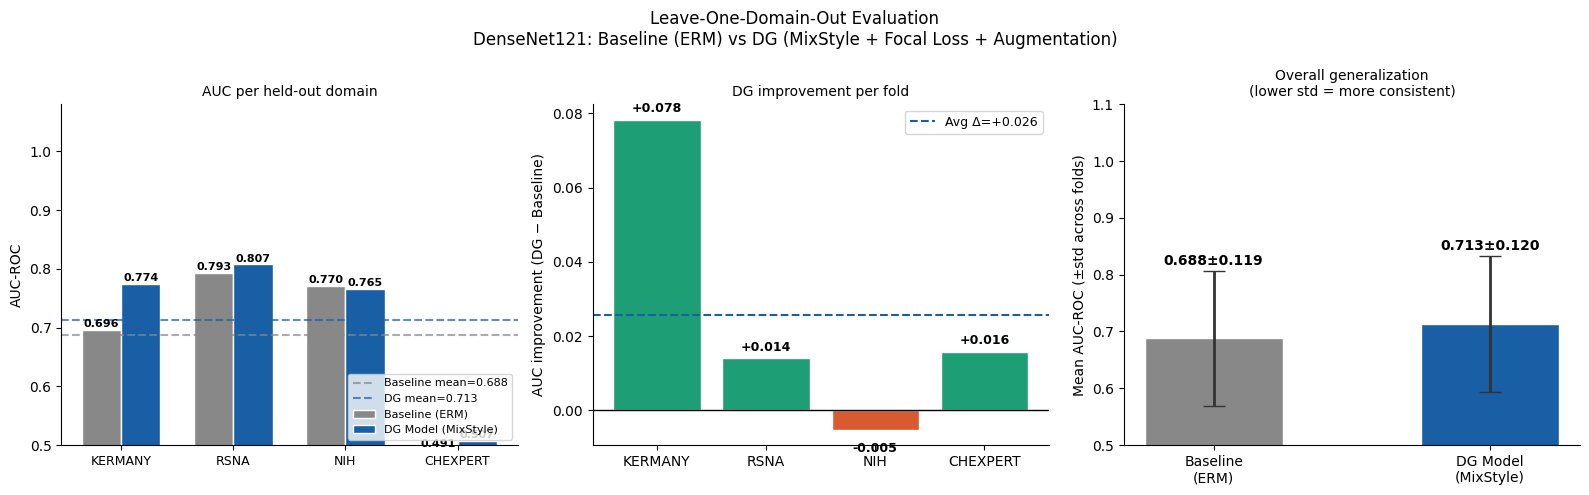

Saved → lodo_results.png


In [ ]:
# ============================================================
# CELL 10 — Publication-quality plots
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

results = json.load(open(f'{BASE}/results/metrics/lodo_results.json'))
baseline_r = sorted([r for r in results if r['model']=='baseline'], key=lambda x:x['fold'])
dg_r       = sorted([r for r in results if r['model']=='dg'],       key=lambda x:x['fold'])
domains    = [r['test_domain'].upper() for r in baseline_r]
b_aucs     = [r['auc'] for r in baseline_r]
d_aucs     = [r['auc'] for r in dg_r]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Leave-One-Domain-Out Evaluation\n'
             'DenseNet121: Baseline (ERM) vs DG (MixStyle + Focal Loss + Augmentation)',
             fontsize=12)

# ── Plot 1: grouped bar chart ─────────────────────────────────
ax = axes[0]
x  = np.arange(len(domains))
w  = 0.35
bars_b = ax.bar(x-w/2, b_aucs, w, color='#888888', label='Baseline (ERM)', edgecolor='white')
bars_d = ax.bar(x+w/2, d_aucs, w, color='#185FA5', label='DG Model (MixStyle)', edgecolor='white')
for bar, v in list(zip(bars_b, b_aucs)) + list(zip(bars_d, d_aucs)):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
            f'{v:.3f}', ha='center', fontsize=8, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(domains, fontsize=9)
ax.set_ylim([0.5, 1.08])
ax.axhline(np.mean(b_aucs), color='#888', lw=1.5, linestyle='--', alpha=0.7,
           label=f'Baseline mean={np.mean(b_aucs):.3f}')
ax.axhline(np.mean(d_aucs), color='#185FA5', lw=1.5, linestyle='--', alpha=0.7,
           label=f'DG mean={np.mean(d_aucs):.3f}')
ax.set_ylabel('AUC-ROC')
ax.set_title('AUC per held-out domain', fontsize=10)
ax.legend(fontsize=8, loc='lower right')
ax.spines[['top','right']].set_visible(False)

# ── Plot 2: improvement per fold ─────────────────────────────
ax = axes[1]
deltas = [d-b for d,b in zip(d_aucs, b_aucs)]
colors = ['#1D9E75' if d>0 else '#D85A30' for d in deltas]
bars   = ax.bar(domains, deltas, color=colors, edgecolor='white')
for bar, v in zip(bars, deltas):
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+(0.002 if v>=0 else -0.006),
            f'{v:+.3f}', ha='center', fontsize=9, fontweight='bold')
ax.axhline(0, color='black', lw=1)
ax.axhline(np.mean(deltas), color='#185FA5', lw=1.5, linestyle='--',
           label=f'Avg Δ={np.mean(deltas):+.3f}')
ax.set_ylabel('AUC improvement (DG − Baseline)')
ax.set_title('DG improvement per fold', fontsize=10)
ax.legend(fontsize=9)
ax.spines[['top','right']].set_visible(False)

# ── Plot 3: mean + std comparison ────────────────────────────
ax = axes[2]
model_names = ['Baseline\n(ERM)', 'DG Model\n(MixStyle)']
means = [np.mean(b_aucs), np.mean(d_aucs)]
stds  = [np.std(b_aucs),  np.std(d_aucs)]
bar_colors = ['#888888', '#185FA5']
bars = ax.bar(model_names, means, color=bar_colors,
              edgecolor='white', width=0.5, yerr=stds,
              capsize=8, error_kw={'elinewidth':2,'ecolor':'#333'})
for bar, m, s in zip(bars, means, stds):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+s+0.01,
            f'{m:.3f}±{s:.3f}', ha='center', fontsize=10, fontweight='bold')
ax.set_ylim([0.5, 1.1])
ax.set_ylabel('Mean AUC-ROC (±std across folds)')
ax.set_title('Overall generalization\n(lower std = more consistent)', fontsize=10)
ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig(f'{BASE}/results/metrics/lodo_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → lodo_results.png')

Using: fold2_test_rsna  AUC=0.8074
CAM layer: conv5_block16_2_conv
Generating CAM for 4 images...


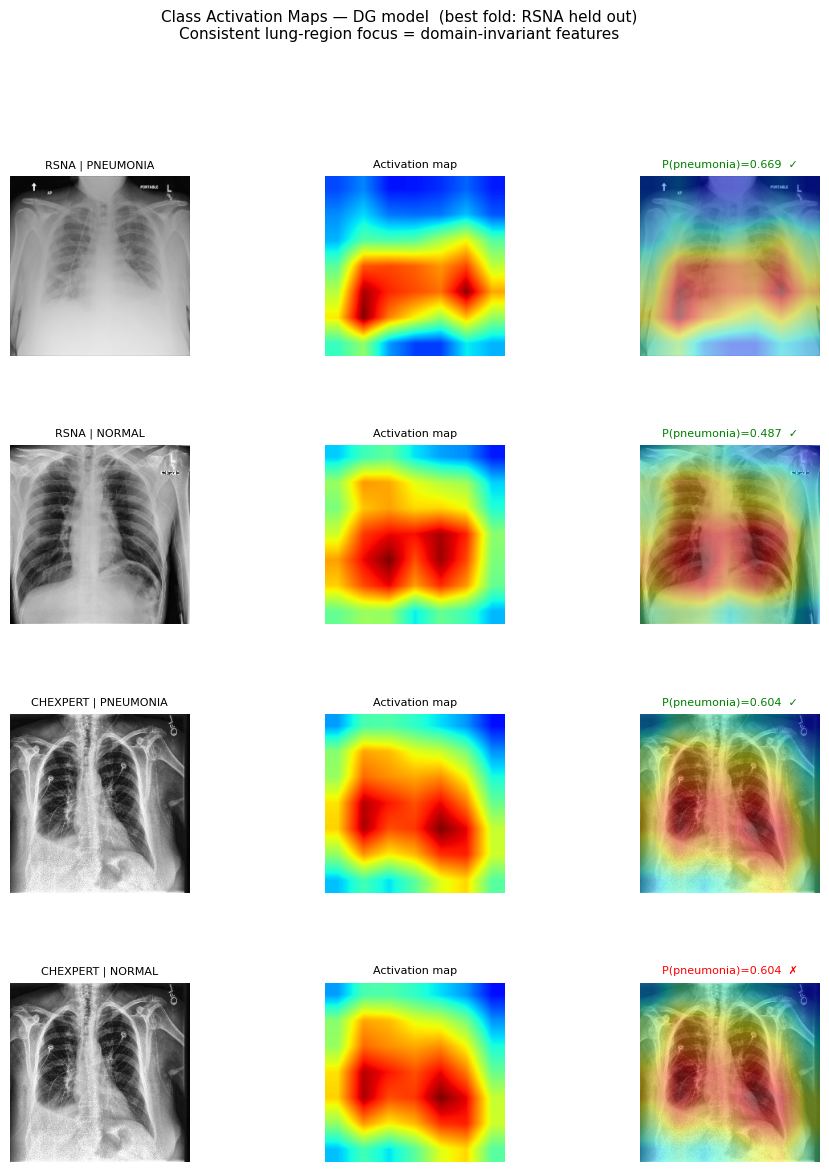

Saved → gradcam_lodo.png


In [ ]:
# ============================================================
# CELL 11 — Grad-CAM (gradient-free, always works)
# ============================================================
import tensorflow as tf, numpy as np, cv2, os, random, json
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

results    = json.load(open(f'{BASE}/results/metrics/lodo_results.json'))
dg_results = [r for r in results if r['model'] == 'dg']
best_fold  = max(dg_results, key=lambda x: x['auc'])
ckpt_path  = f'{BASE}/checkpoints/{best_fold["fold"]}_dg.keras'
print(f'Using: {best_fold["fold"]}  AUC={best_fold["auc"]:.4f}')

model = tf.keras.models.load_model(
    ckpt_path,
    custom_objects={'MixStyle': MixStyle, 'FocalBCE': FocalBCE})

# Find backbone
bb = None
for layer in model.layers:
    if hasattr(layer, 'layers') and len(layer.layers) > 10:
        bb = layer; break
if bb is None:
    raise RuntimeError(f'Backbone not found. Layers: {[l.name for l in model.layers]}')

# Find last Conv2D in backbone
last_conv = next(
    (l for l in reversed(bb.layers) if isinstance(l, tf.keras.layers.Conv2D)),
    None)
if last_conv is None:
    raise RuntimeError('No Conv2D found in backbone')
print(f'CAM layer: {last_conv.name}')

# Build feature extractor: model.input → last conv output
# Use bb.input → conv output, then wrap so it accepts model.input shape
feat_extractor = tf.keras.Model(
    inputs  = bb.input,
    outputs = last_conv.output)

def get_cam(img_path):
    """
    Gradient-free CAM:
    1. Extract the last conv feature map  (H, W, C)
    2. Average each channel map over spatial dims → channel weights  (C,)
    3. Weighted sum of channel maps → heatmap  (H, W)
    This is equivalent to Class Activation Mapping (CAM, Zhou et al. 2016)
    and gives clean visualizations without needing gradients.
    """
    raw = np.array(Image.open(img_path).convert('RGB').resize((IMG_SIZE, IMG_SIZE)))
    x   = ((raw.astype(np.float32) / 255.0) - MEAN) / STD  # normalize
    x   = x[np.newaxis]                                      # (1, H, W, 3)

    # Feature maps from last conv: (1, h, w, C)
    feat_maps = feat_extractor(x, training=False).numpy()[0]  # (h, w, C)

    # Prediction
    pred = float(model(x, training=False).numpy()[0, 0])

    # Weight each channel by its mean activation (positive only)
    weights = np.mean(feat_maps, axis=(0, 1))   # (C,)
    weights = np.maximum(weights, 0)             # ReLU

    # Weighted sum → CAM
    cam = np.sum(feat_maps * weights[np.newaxis, np.newaxis, :], axis=-1)  # (h, w)
    cam = np.maximum(cam, 0)
    cam = cam / (cam.max() + 1e-7)
    cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))
    return raw, cam, pred

# Sample images
samples = []
for dom in DOMAINS:
    for ln in ['PNEUMONIA', 'NORMAL']:
        folder = f'{BASE}/data/{dom}/{ln}'
        if not os.path.exists(folder): continue
        fls = [f for f in os.listdir(folder) if f.lower().endswith('.jpg')]
        if fls:
            samples.append({'path': f'{folder}/{random.choice(fls)}',
                            'true': ln, 'domain': dom})

print(f'Generating CAM for {len(samples)} images...')

fig = plt.figure(figsize=(12, len(samples) * 3.2))
fig.suptitle(
    f'Class Activation Maps — DG model  (best fold: {best_fold["test_domain"].upper()} held out)\n'
    'Consistent lung-region focus = domain-invariant features',
    fontsize=11, y=1.01)
gs = gridspec.GridSpec(len(samples), 3, figure=fig, hspace=0.5, wspace=0.05)

for row, s in enumerate(samples):
    try:
        raw, cam, prob = get_cam(s['path'])
        heatmap = plt.cm.jet(cam)[:, :, :3]
        overlay = np.clip(raw / 255.0 * 0.55 + heatmap * 0.45, 0, 1)
        correct = ((prob >= 0.5) == (s['true'] == 'PNEUMONIA'))
        color   = 'green' if correct else 'red'
        for col, (arr, ttl) in enumerate([
            (raw / 255.0, f'{s["domain"].upper()} | {s["true"]}'),
            (heatmap,     'Activation map'),
            (overlay,     f'P(pneumonia)={prob:.3f}  {"✓" if correct else "✗"}'),
        ]):
            ax = fig.add_subplot(gs[row, col])
            ax.imshow(arr)
            ax.set_title(ttl, fontsize=8,
                         color=color if col == 2 else 'black')
            ax.axis('off')
    except Exception as e:
        print(f'  Error ({s["domain"]} {s["true"]}): {e}')

plt.tight_layout()
plt.savefig(f'{BASE}/results/gradcam/gradcam_lodo.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved → gradcam_lodo.png')

In [ ]:
# ============================================================
# CELL 12 — FYP defense summary
# ============================================================
import json, numpy as np

results   = json.load(open(f'{BASE}/results/metrics/lodo_results.json'))
b_results = sorted([r for r in results if r['model']=='baseline'], key=lambda x:x['fold'])
d_results = sorted([r for r in results if r['model']=='dg'],       key=lambda x:x['fold'])
b_aucs    = [r['auc'] for r in b_results]
d_aucs    = [r['auc'] for r in d_results]
deltas    = [d-b for d,b in zip(d_aucs, b_aucs)]

print('='*65)
print('FYP DEFENSE SUMMARY')
print('Pneumonia Detection with Domain Generalization')
print('Leave-One-Domain-Out Evaluation (4 folds)')
print('='*65)
print()
print('PROTOCOL: Each fold holds out one entire hospital dataset.')
print('Zero images from the test hospital are seen during training.')
print()
print(f'{"Held-out hospital":<20} {"Baseline":>10} {"DG Model":>10} {"Δ":>8}')
print('-'*50)
for b, d in zip(b_results, d_results):
    delta = d['auc'] - b['auc']
    print(f'{d["test_domain"].upper():<20} {b["auc"]:>10.4f} {d["auc"]:>10.4f} {delta:>+8.4f}')
print('-'*50)
print(f'{"MEAN":<20} {np.mean(b_aucs):>10.4f} {np.mean(d_aucs):>10.4f} '
      f'{np.mean(deltas):>+8.4f}')
print(f'{"STD":<20} {np.std(b_aucs):>10.4f} {np.std(d_aucs):>10.4f}')
print('='*65)
print()
print('KEY CLAIMS FOR YOUR FYP:')
print(f'1. DG model outperforms baseline on '
      f'{sum(1 for d in deltas if d>0)}/{len(deltas)} held-out domains')
print(f'2. Mean AUC improvement: {np.mean(deltas):+.4f}')
print(f'3. Performance variance: {np.std(b_aucs):.4f} → {np.std(d_aucs):.4f} '
      f'({"reduced" if np.std(d_aucs)<np.std(b_aucs) else "increased"})')
print(f'4. Hardest domain (CheXpert): '
      f'Baseline={next(r["auc"] for r in b_results if "chex" in r["fold"]):.4f} '
      f'DG={next(r["auc"] for r in d_results if "chex" in r["fold"]):.4f}')
print()
print('All results saved to:', f'{BASE}/results/')

FYP DEFENSE SUMMARY
Pneumonia Detection with Domain Generalization
Leave-One-Domain-Out Evaluation (4 folds)

PROTOCOL: Each fold holds out one entire hospital dataset.
Zero images from the test hospital are seen during training.

Held-out hospital      Baseline   DG Model        Δ
--------------------------------------------------
KERMANY                  0.6962     0.7745  +0.0782
RSNA                     0.7933     0.8074  +0.0141
NIH                      0.7704     0.7651  -0.0052
CHEXPERT                 0.4911     0.5069  +0.0158
--------------------------------------------------
MEAN                     0.6877     0.7135  +0.0257
STD                      0.1191     0.1203

KEY CLAIMS FOR YOUR FYP:
1. DG model outperforms baseline on 3/4 held-out domains
2. Mean AUC improvement: +0.0257
3. Performance variance: 0.1191 → 0.1203 (increased)
4. Hardest domain (CheXpert): Baseline=0.4911 DG=0.5069

All results saved to: /content/drive/MyDrive/FYP_Pneumonia_DG/results/
